# Task 2 (Easy) - Exploratory Data Analysis (EDA)
- **Description:** Explore the Netflix dataset to uncover trends, patterns, and insights.

## Step 1: Analyze dataset structure and statistics

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Cleaned dataset from Task 1
data = pd.read_csv("Cleaned_Netflix_Dataset.csv")
data.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,year_added,month_added,years_to_netflix,duration_value,primary_country,country_count,genre_count,audience
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,2021,9,1,90,United States,1,1,Teens
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",2021,9,0,1,France,1,3,Adults
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",2021,9,0,1,United States,1,3,Adults
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",2021,9,0,91,Brazil,1,2,Older Kids
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",2021,9,28,125,United States,1,3,Adults


In [3]:
print("Shape:", data.shape)
data.info()

Shape: (8790, 18)
<class 'pandas.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   show_id           8790 non-null   str  
 1   type              8790 non-null   str  
 2   title             8790 non-null   str  
 3   director          8790 non-null   str  
 4   country           8790 non-null   str  
 5   date_added        8790 non-null   str  
 6   release_year      8790 non-null   int64
 7   rating            8790 non-null   str  
 8   duration          8790 non-null   str  
 9   listed_in         8790 non-null   str  
 10  year_added        8790 non-null   int64
 11  month_added       8790 non-null   int64
 12  years_to_netflix  8790 non-null   int64
 13  duration_value    8790 non-null   int64
 14  primary_country   8790 non-null   str  
 15  country_count     8790 non-null   int64
 16  genre_count       8790 non-null   int64
 17  audience          8790 non

In [4]:
data.describe()

,release_year,year_added,month_added,years_to_netflix,duration_value,country_count,genre_count
count,8790.000000,8790.000000,8790.000000,8790.000000,8790.000000,8790.0,8790.000000
mean,2014.183163,2018.873606,6.655859,4.692378,69.934471,1.0,2.194994
std,8.825466,1.573568,3.436103,8.788835,50.794433,0.0,0.784114
min,1925.000000,2008.000000,1.000000,0.000000,1.000000,1.0,1.000000
25%,2013.000000,2018.000000,4.000000,0.000000,2.000000,1.0,2.000000
50%,2017.000000,2019.000000,7.000000,1.000000,88.500000,1.0,2.000000
75%,2019.000000,2020.000000,10.000000,5.000000,106.000000,1.0,3.000000
max,2021.000000,2021.000000,12.000000,93.000000,312.000000,1.0,3.000000


## Step 2: Study content distribution by type

In [5]:
type_counts = data["type"].value_counts()
type_percent = (data["type"].value_counts(normalize=True) * 100).round(1)
pd.DataFrame({"count": type_counts, "percent": type_percent})

,count,percent
type,,
Movie,6126,69.7
TV Show,2664,30.3


## Step 3: Identify top countries and categories

In [6]:
# Top 10 countries (ignoring 'Unknown')
top_countries = data.loc[data["country"] != "Unknown", "country"].value_counts().head(10)
top_countries

country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Name: count, dtype: int64

In [7]:
# Top 10 categories (a title can have several, so split first)
top_genres = data["listed_in"].str.split(",").explode().str.strip().value_counts().head(10)
top_genres

listed_in
International Movies        2752
Dramas                      2426
Comedies                    1674
International TV Shows      1349
Documentaries                869
Action & Adventure           859
TV Dramas                    762
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64

## Step 4: Creating visualizations for key metrics.

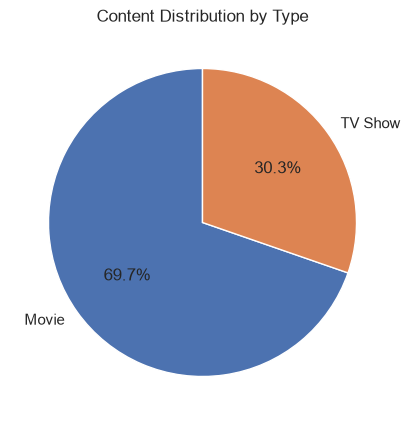

In [12]:
# 1. Movies vs TV Shows
plt.figure(figsize=(5, 5))
plt.pie(type_counts, labels=type_counts.index, autopct="%1.1f%%", startangle=90)
plt.title("Content Distribution by Type")
plt.show()

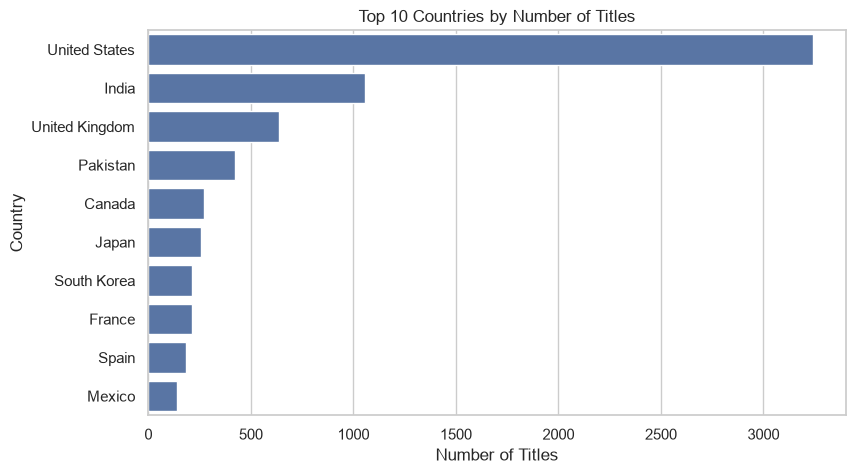

In [9]:
# 2. Top 10 countries
plt.figure(figsize=(9, 5))
sns.barplot(x=top_countries.values, y=top_countries.index)
plt.title("Top 10 Countries by Number of Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.show()

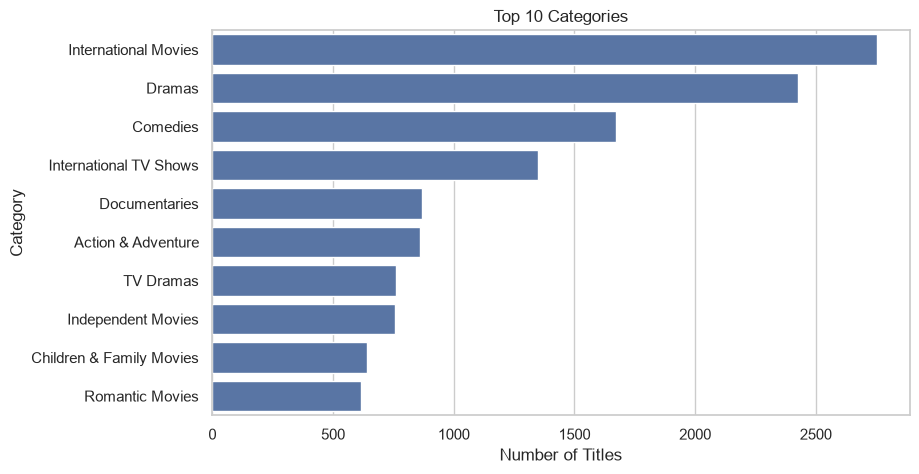

In [10]:
# 3. Top 10 categories
plt.figure(figsize=(9, 5))
sns.barplot(x=top_genres.values, y=top_genres.index)
plt.title("Top 10 Categories")
plt.xlabel("Number of Titles")
plt.ylabel("Category")
plt.show()

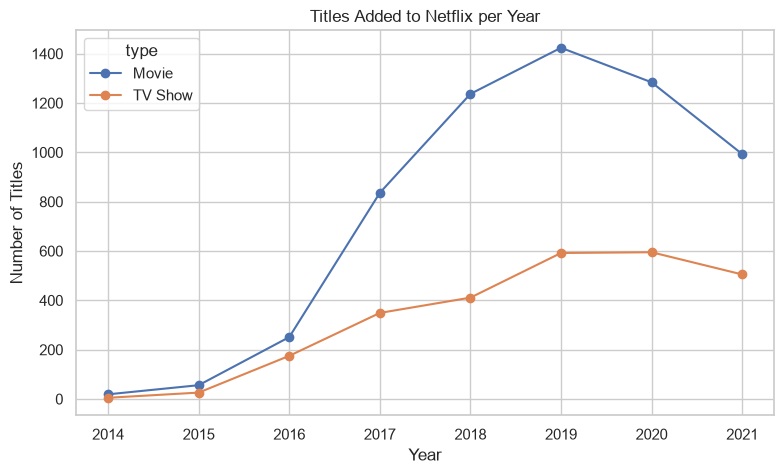

In [11]:
# 4. Trend: titles added per year
yearly = data.groupby(["year_added", "type"]).size().unstack()
yearly = yearly[yearly.index >= 2014]

yearly.plot(marker="o", figsize=(9, 5))
plt.title("Titles Added to Netflix per Year")
plt.xlabel("Year")
plt.ylabel("Number of Titles")
plt.show()

## Step 5: Summarize findings

- The dataset has **8,790 titles**: **69.7% Movies** (6,126) and **30.3% TV Shows** (2,664).
- The **United States** has the most titles (3,240), followed by **India** (1,057), the **United Kingdom** (638), **Pakistan** (421) and **Canada** (271).
- The most common categories are **International Movies** (2,752), **Dramas** (2,426) and **Comedies** (1,674).
- Content added per year grew quickly from 2016 and peaked around **2019-2020**. 2021 is lower because the data ends in September 2021.
- Overall, Netflix's catalogue is movie-heavy, led by the US and India, with drama and international content as the biggest categories.